Module : Crop Yield Prediction

Input: Rainfall, temperature, humidity, evaporation

In [ ]:

import numpy as np
import pandas as pd

np.random.seed(42)

crops = ["Rice", "Sorghum", "Maize", "Groundnut", "Sugarcane"]

data = []

for crop in crops:
    for i in range(150):

        rainfall = np.random.uniform(300, 1200)
        min_temp = np.random.uniform(15, 27)
        max_temp = np.random.uniform(25, 40)
        humidity = np.random.uniform(40, 90)
        evaporation = np.random.uniform(2, 9)

        climate_score = (
            0.35 * rainfall / 1200
            + 0.20 * humidity / 100
            + 0.15 * min_temp / 30
            - 0.15 * max_temp / 45
            - 0.15 * evaporation / 12
        )

        low, high = {
            "Rice": (2, 5),
            "Sorghum": (0.5, 2.5),
            "Maize": (2, 6),
            "Groundnut": (1, 3),
            "Sugarcane": (50, 100)
        }[crop]

        yield_value = low + (
            (climate_score - 0.1) / 0.6
        ) * (high - low)

        yield_value += np.random.normal(0, (high-low)*0.03)
        yield_value = np.clip(yield_value, low, high)

        data.append([
            crop, rainfall, min_temp, max_temp,
            humidity, evaporation, yield_value
        ])

climate_df = pd.DataFrame(data, columns=[
    "Crop", "Rainfall", "Min_Temp",
    "Max_Temp", "Humidity", "Evaporation", "Yield"
])

print(climate_df.head())
print("Total records:", len(climate_df))


   Crop    Rainfall   Min_Temp   Max_Temp   Humidity  Evaporation     Yield
0  Rice  637.086107  26.408572  35.979909  69.932924     3.092130  3.020818
1  Rice  937.265320  15.247014  39.548648  81.622132     3.486374  3.278146
2  Rice  463.642470  17.200854  29.563634  66.237822     5.023615  2.535322
3  Rice  425.544475  18.505736  30.495428  62.803499     7.496232  2.097344
4  Rice  479.706404  21.170813  33.886219  42.322521     6.252814  2.142473
Total records: 750


In [ ]:

import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

features = [
    "Rainfall", "Min_Temp", "Max_Temp",
    "Humidity", "Evaporation"
]

class ANFIS(nn.Module):
    def __init__(self, n_inputs=5, n_mfs=3):
        super().__init__()

        import itertools

        self.centers = nn.Parameter(
            torch.linspace(-1, 1, n_mfs).repeat(n_inputs, 1)
        )

        self.log_sigma = nn.Parameter(
            torch.zeros(n_inputs, n_mfs)
        )

        self.rules = torch.tensor(
            list(itertools.product(range(n_mfs), repeat=n_inputs)),
            dtype=torch.long
        )

        self.consequents = nn.Parameter(
            torch.randn(n_mfs**n_inputs, n_inputs+1) * 0.01
        )

    def forward(self, x):
        sigma = torch.exp(self.log_sigma).clamp(min=0.05)

        diff = x.unsqueeze(2) - self.centers.unsqueeze(0)

        membership = torch.exp(
            -0.5 * (diff / sigma.unsqueeze(0))**2
        )

        rules = self.rules.to(x.device)

        # Safely extract membership values for each rule combination
        # membership shape: (batch_size, n_inputs, n_mfs)
        # rules shape: (n_rules, n_inputs)
        # We want to select membership[:, i, rules[:, i]] for each input i
        batch_size = x.shape[0]
        n_rules = rules.shape[0]

        # Prepare gather index
        selected = torch.stack([
            membership[:, i, rules[:, i]] for i in range(x.shape[1])
        ], dim=1) # Shape: (batch_size, n_inputs, n_rules)

        firing = torch.softmax(
            torch.log(selected.clamp(min=1e-10)).sum(dim=1),
            dim=1
        ) # Shape: (batch_size, n_rules)

        x_extended = torch.cat(
            [x, torch.ones(x.shape[0], 1, device=x.device)],
            dim=1
        ) # Shape: (batch_size, n_inputs + 1)

        output = x_extended @ self.consequents.T # Shape: (batch_size, n_rules)

        return torch.sum(
            firing * output, dim=1, keepdim=True
        )


models_anfis = {}
scalers_anfis = {}
results = []

for crop in crops:

    df = climate_df[climate_df["Crop"] == crop]

    X = df[features].values
    y = df[["Yield"]].values

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=42
    )

    sx, sy = StandardScaler(), StandardScaler()

    X_train = sx.fit_transform(X_train)
    X_test = sx.transform(X_test)

    y_train = sy.fit_transform(y_train)

    Xt = torch.tensor(X_train, dtype=torch.float32, device=device)
    yt = torch.tensor(y_train, dtype=torch.float32, device=device)
    Xv = torch.tensor(X_test, dtype=torch.float32, device=device)

    model = ANFIS().to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=0.005)
    criterion = nn.MSELoss()

    for epoch in range(300):
        optimizer.zero_grad()
        loss = criterion(model(Xt), yt)
        loss.backward()
        optimizer.step()

    model.eval()

    with torch.no_grad():
        pred = model(Xv).cpu().numpy()

    pred = sy.inverse_transform(pred)

    r2 = r2_score(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)

    models_anfis[crop] = model
    scalers_anfis[crop] = (sx, sy)

    results.append([crop, r2, rmse, mae])

    print(crop, "R2:", round(r2, 3),
          "RMSE:", round(rmse, 3),
          "MAE:", round(mae, 3))

anfis_results = pd.DataFrame(
    results, columns=["Crop", "R2", "RMSE", "MAE"]
)

display(anfis_results)

Rice R2: 0.896 RMSE: 0.153 MAE: 0.129
Sorghum R2: 0.833 RMSE: 0.102 MAE: 0.077
Maize R2: 0.79 RMSE: 0.254 MAE: 0.184
Groundnut R2: 0.867 RMSE: 0.106 MAE: 0.084
Sugarcane R2: 0.804 RMSE: 2.92 MAE: 2.339


,Crop,R2,RMSE,MAE
0,Rice,0.896066,0.153494,0.128537
1,Sorghum,0.832596,0.101578,0.076831
2,Maize,0.790462,0.253568,0.184348
3,Groundnut,0.866534,0.105844,0.084144
4,Sugarcane,0.804477,2.920475,2.338719


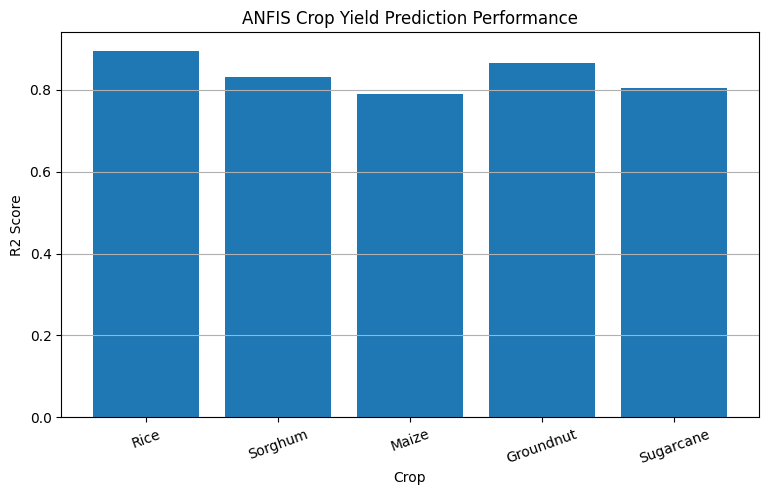

In [ ]:

plt.figure(figsize=(9, 5))

plt.bar(
    anfis_results["Crop"],
    anfis_results["R2"]
)

plt.title("ANFIS Crop Yield Prediction Performance")
plt.xlabel("Crop")
plt.ylabel("R2 Score")
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.show()


In [ ]:

def predict_crop_yield(crop, rainfall, min_temp,
                       max_temp, humidity, evaporation):

    sx, sy = scalers_anfis[crop]

    values = np.array([[
        rainfall, min_temp, max_temp,
        humidity, evaporation
    ]])

    values = sx.transform(values)

    x = torch.tensor(
        values, dtype=torch.float32, device=device
    )

    model = models_anfis[crop]
    model.eval()

    with torch.no_grad():
        prediction = model(x).cpu().numpy()

    prediction = sy.inverse_transform(prediction)

    print("Crop:", crop)
    print("Predicted Yield:",
          round(float(prediction[0][0]), 3),
          "tonnes/hectare")

    return float(prediction[0][0])


predict_crop_yield(
    "Sugarcane", 800, 20, 32, 70, 5
)


Crop: Sugarcane
Predicted Yield: 65.897 tonnes/hectare


65.89653778076172

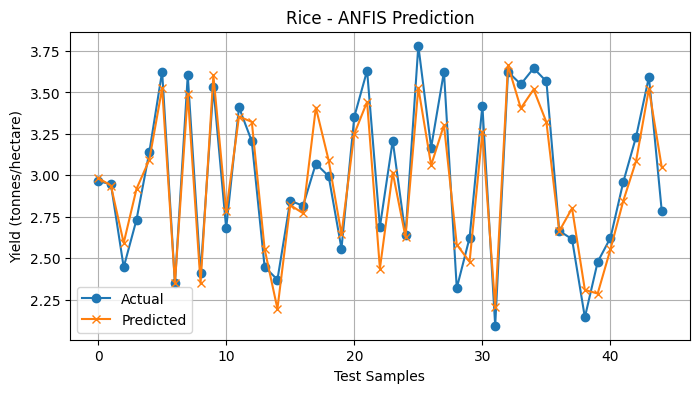

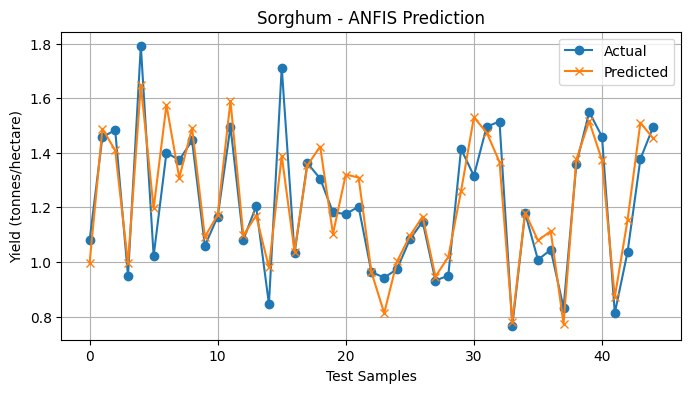

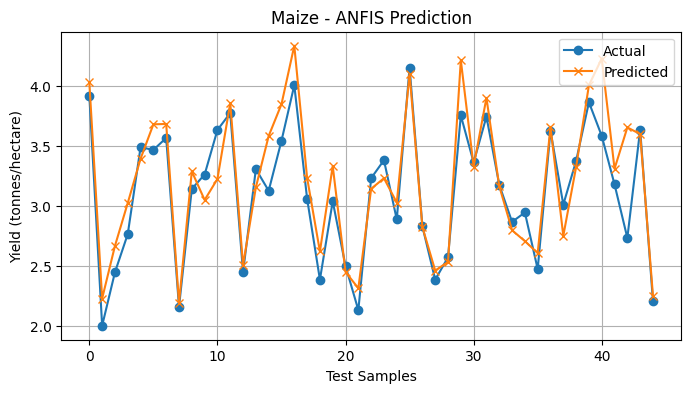

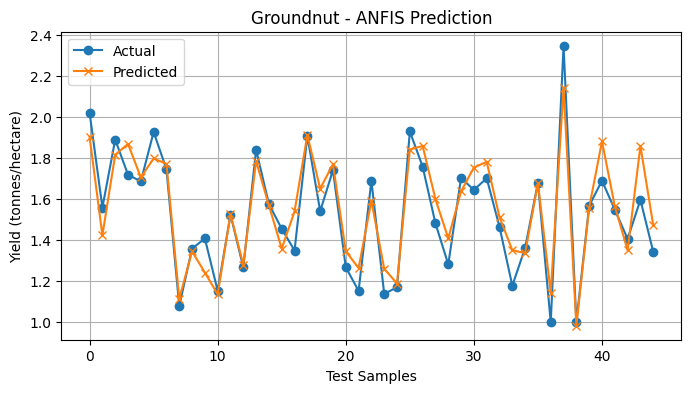

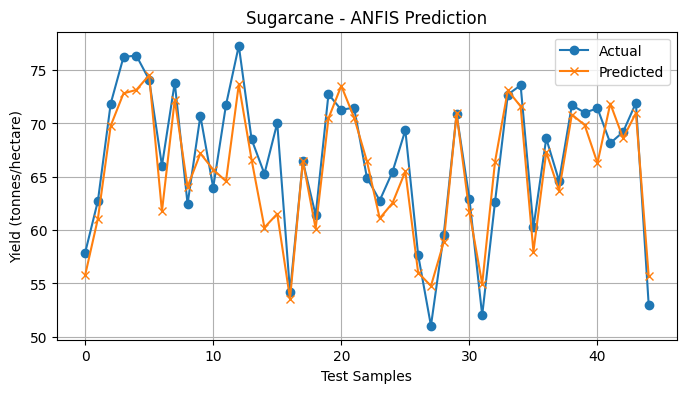

In [ ]:

import matplotlib.pyplot as plt
import torch

for crop in crops:

    df = climate_df[climate_df["Crop"] == crop]

    X = df[features].values
    y = df["Yield"].values.reshape(-1, 1)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.30, random_state=42
    )

    sx, sy = scalers_anfis[crop]

    X_test = sx.transform(X_test)

    xt = torch.tensor(
        X_test, dtype=torch.float32, device=device
    )

    model = models_anfis[crop]
    model.eval()

    with torch.no_grad():
        pred = model(xt).cpu().numpy()

    pred = sy.inverse_transform(pred)

    plt.figure(figsize=(8, 4))
    plt.plot(y_test, label="Actual", marker="o")
    plt.plot(pred, label="Predicted", marker="x")
    plt.title(f"{crop} - ANFIS Prediction")
    plt.xlabel("Test Samples")
    plt.ylabel("Yield (tonnes/hectare)")
    plt.legend()
    plt.grid()
    plt.show()


In [ ]:

import os
import joblib
import shutil

os.makedirs("Final_Project", exist_ok=True)

# Save CNN
cnn_model.save("Final_Project/Plant_Disease_CNN.keras")

# Save ANFIS models and scalers
for crop in crops:

    torch.save(
        models_anfis[crop].state_dict(),
        f"Final_Project/{crop}_ANFIS.pth"
    )

    joblib.dump(
        scalers_anfis[crop],
        f"Final_Project/{crop}_scalers.pkl"
    )

# Save results
anfis_results.to_csv(
    "Final_Project/ANFIS_Results.csv",
    index=False
)

print("All models and results saved!")


All models and results saved!
